# Policy Metadata Exploration

This notebook joins the frame metadata and L8/L24 feature-similarity tables, then visualizes online/offline metadata separability and runs grouped CV baselines for L24 similarity drift.

Feature families:

- online metadata: timing plus ego pose/motion fields available before encoder execution
- offline metadata: all numeric metadata fields, including GT/object-derived analysis signals
- online metadata + L8: online metadata plus L8 adjacent-frame feature similarity
- offline metadata + L8: offline metadata plus L8 adjacent-frame feature similarity

Outputs are saved under `outputs/policy_signal_stats/val/explore/`.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score, log_loss, mean_absolute_error, r2_score
from sklearn.model_selection import GroupKFold
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 160)

ROOT = Path("..").resolve() if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "outputs/policy_signal_stats/val"
EXPLORE_DIR = DATA_DIR / "explore"
EXPLORE_DIR.mkdir(parents=True, exist_ok=True)

META_CSV = DATA_DIR / "policy_signal_stats.csv"
SIM_CSV = DATA_DIR / "policy_feature_similarity.csv"
META_CSV, SIM_CSV, EXPLORE_DIR


(PosixPath('/home/moshekimhi_google_com/StreamPETR/outputs/policy_signal_stats/val/policy_signal_stats.csv'),
 PosixPath('/home/moshekimhi_google_com/StreamPETR/outputs/policy_signal_stats/val/policy_feature_similarity.csv'),
 PosixPath('/home/moshekimhi_google_com/StreamPETR/outputs/policy_signal_stats/val/explore'))

## Load And Join Tables

Scene starts are removed because adjacent-frame similarity is undefined there.


In [2]:
meta = pd.read_csv(META_CSV)
sim = pd.read_csv(SIM_CSV)

df = meta.merge(sim, on=["token", "scene_token"], suffixes=("", "_sim"))
df = df[(df["has_previous_frame"] == 1) & df["similarity_L24_mean"].notna()].copy()
df = df.sort_values(["scene_token", "frame_number"]).reset_index(drop=True)

df["l24_drift"] = 1.0 - df["similarity_L24_mean"]
df["min_L24_similarity"] = df[[c for c in df.columns if c.startswith("similarity_L24_CAM_")]].min(axis=1)
df["min_L8_similarity"] = df[[c for c in df.columns if c.startswith("similarity_L8_CAM_")]].min(axis=1)
df["L24_camera_spread"] = df[[c for c in df.columns if c.startswith("similarity_L24_CAM_")]].max(axis=1) - df[[c for c in df.columns if c.startswith("similarity_L24_CAM_")]].min(axis=1)

df["difficulty"] = pd.cut(
    df["similarity_L24_mean"],
    bins=[-np.inf, 0.65, 0.80, np.inf],
    labels=["hard", "medium", "easy"],
)

print(f"rows: {len(df)}")
print(f"scenes: {df.scene_token.nunique()}")
df[["token", "scene_token", "frame_number", "similarity_L24_mean", "l24_drift", "difficulty"]].head()


rows: 5869
scenes: 150


,token,scene_token,frame_number,similarity_L24_mean,l24_drift,difficulty
0,0f5cbb909e9544dd861dc2ff63ac4d13,01452fbfbf4543af8acdfd3e8a1ee806,1,0.957917,0.042083,easy
1,da74550a10a8408299d7e6b1735963ae,01452fbfbf4543af8acdfd3e8a1ee806,2,0.955903,0.044097,easy
2,cf86af90b622499b8214df0024a6ea29,01452fbfbf4543af8acdfd3e8a1ee806,3,0.956075,0.043925,easy
3,901cfd30cb2a4fdba55095f9ec0fed34,01452fbfbf4543af8acdfd3e8a1ee806,4,0.958027,0.041973,easy
4,5c9d217c4af14c608c7b5f9469dd488b,01452fbfbf4543af8acdfd3e8a1ee806,5,0.955480,0.044520,easy


## Feature Sets

The online set intentionally excludes annotation counts, object distances/sizes/velocities, camera annotation counts, 2D box areas, and new/disappeared object proxies.


In [3]:
ONLINE_METADATA = [
    "frame_number",
    "info_frame_idx",
    "is_scene_start",
    "dt_s",
    "ego_x_m",
    "ego_y_m",
    "ego_z_m",
    "ego_yaw_deg",
    "delta_ego_translation_m",
    "ego_speed_mps",
    "ego_accel_mps2",
    "yaw_rate_deg_s",
    "abs_yaw_rate_deg_s",
    "yaw_accel_deg_s2",
    "abs_yaw_accel_deg_s2",
]

NON_FEATURE = {"index", "token", "scene_token", "timestamp", "has_previous_frame", "similarity_L24_mean", "l24_drift"}
OFFLINE_METADATA = [
    c for c in meta.columns
    if c not in NON_FEATURE and pd.api.types.is_numeric_dtype(meta[c])
]

L8_FEATURES = [c for c in df.columns if c.startswith("similarity_L8_")]

FEATURE_SETS = {
    "metadata_online": ONLINE_METADATA,
    "metadata_offline": OFFLINE_METADATA,
    "metadata_online_plus_L8": ONLINE_METADATA + L8_FEATURES,
    "metadata_offline_plus_L8": OFFLINE_METADATA + L8_FEATURES,
}

pd.DataFrame({"feature_set": FEATURE_SETS.keys(), "n_features": [len(v) for v in FEATURE_SETS.values()]})


,feature_set,n_features
0,metadata_online,15
1,metadata_offline,42
2,metadata_online_plus_L8,22
3,metadata_offline_plus_L8,49


# Stage A: Exploratory Separability

These plots inspect target distributions, simple feature-target relationships, label separability, scene balance, and per-camera behavior.


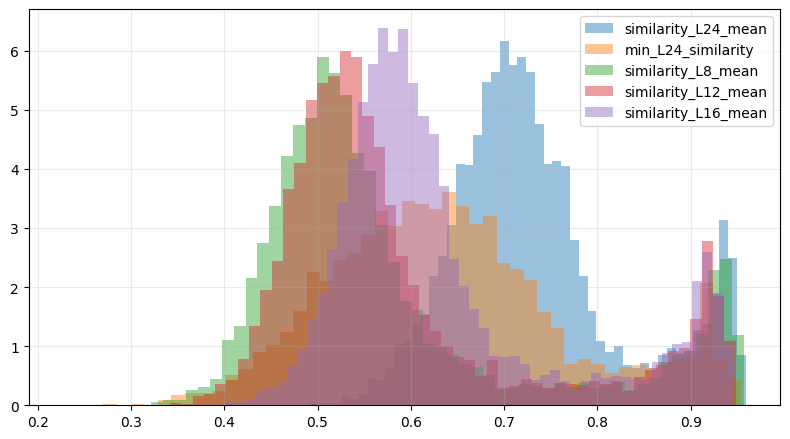

/home/moshekimhi_google_com/StreamPETR/outputs/policy_signal_stats/val/explore/target_and_layer_similarity_distributions.png


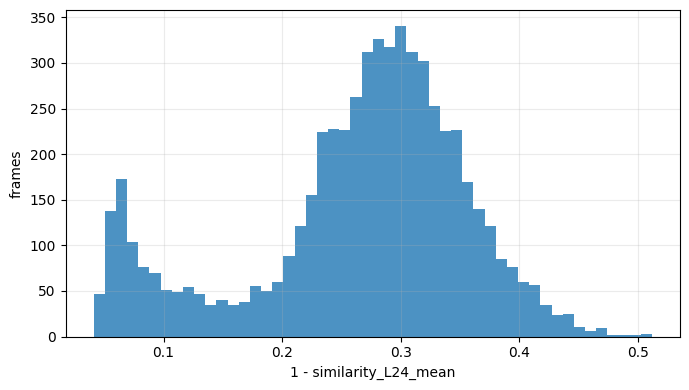

/home/moshekimhi_google_com/StreamPETR/outputs/policy_signal_stats/val/explore/l24_drift_distribution.png


In [4]:
def savefig(name):
    path = EXPLORE_DIR / name
    plt.tight_layout()
    plt.savefig(path, dpi=160)
    plt.show()
    print(path)


def hist_series(columns, bins=50, name="hist.png"):
    plt.figure(figsize=(8, 4.5))
    for col in columns:
        plt.hist(df[col].dropna(), bins=bins, alpha=0.45, density=True, label=col)
    plt.legend()
    plt.grid(alpha=0.25)
    savefig(name)

hist_series(
    ["similarity_L24_mean", "min_L24_similarity", "similarity_L8_mean", "similarity_L12_mean", "similarity_L16_mean"],
    name="target_and_layer_similarity_distributions.png",
)

plt.figure(figsize=(7, 4))
plt.hist(df["l24_drift"], bins=50, alpha=0.8)
plt.xlabel("1 - similarity_L24_mean")
plt.ylabel("frames")
plt.grid(alpha=0.25)
savefig("l24_drift_distribution.png")


In [5]:
df

,index,token,scene_token,frame_number,info_frame_idx,is_scene_start,timestamp,dt_s,ego_x_m,ego_y_m,ego_z_m,ego_yaw_deg,delta_ego_translation_m,ego_speed_mps,ego_accel_mps2,yaw_rate_deg_s,abs_yaw_rate_deg_s,yaw_accel_deg_s2,abs_yaw_accel_deg_s2,num_annotations,avg_object_distance_m,median_object_distance_m,min_object_distance_m,p10_object_distance_m,p90_object_distance_m,near_object_count_10m,near_object_count_20m,near_object_count_30m,near_object_count_50m,avg_box_length_m,avg_box_width_m,avg_box_height_m,avg_box_volume_m3,avg_box_area_m2,avg_object_speed_mps,max_object_speed_mps,camera_annotation_count,max_camera_annotation_count,min_camera_annotation_count,avg_camera_annotation_count,avg_2d_box_area_px,max_2d_box_area_px,new_object_proxy_count,matched_object_proxy_count,disappeared_object_proxy_count,new_object_proxy_fraction,frame_number_sim,queue_frame_index,has_previous_frame,similarity_L12_CAM_BACK,similarity_L12_CAM_BACK_LEFT,similarity_L12_CAM_BACK_RIGHT,similarity_L12_CAM_FRONT,similarity_L12_CAM_FRONT_LEFT,similarity_L12_CAM_FRONT_RIGHT,similarity_L12_mean,similarity_L16_CAM_BACK,similarity_L16_CAM_BACK_LEFT,similarity_L16_CAM_BACK_RIGHT,similarity_L16_CAM_FRONT,similarity_L16_CAM_FRONT_LEFT,similarity_L16_CAM_FRONT_RIGHT,similarity_L16_mean,similarity_L24_CAM_BACK,similarity_L24_CAM_BACK_LEFT,similarity_L24_CAM_BACK_RIGHT,similarity_L24_CAM_FRONT,similarity_L24_CAM_FRONT_LEFT,similarity_L24_CAM_FRONT_RIGHT,similarity_L24_mean,similarity_L8_CAM_BACK,similarity_L8_CAM_BACK_LEFT,similarity_L8_CAM_BACK_RIGHT,similarity_L8_CAM_FRONT,similarity_L8_CAM_FRONT_LEFT,similarity_L8_CAM_FRONT_RIGHT,similarity_L8_mean,l24_drift,min_L24_similarity,min_L8_similarity,L24_camera_spread,difficulty
0,835,0f5cbb909e9544dd861dc2ff63ac4d13,01452fbfbf4543af8acdfd3e8a1ee806,1,1,0,1533151515047378,0.500331,593.427590,1511.444550,0.0,149.193285,0.000009,0.000017,0.000035,-0.004985,0.004985,-0.009963,0.009963,46,21.121543,17.636881,5.249152,6.183381,42.844192,9,27,36,45,2.022000,0.958391,1.542283,12.062149,4.227051,0.100275,1.778724,55,17,2,9.166667,46531.294881,9.037746e+05,3,43,0,0.065217,1,0,1,0.942967,0.948206,0.964272,0.918704,0.942272,0.958644,0.945844,0.941569,0.947353,0.961949,0.914266,0.938103,0.955393,0.943105,0.956798,0.963261,0.974279,0.933366,0.950225,0.969574,0.957917,0.948051,0.956514,0.971211,0.933044,0.953490,0.965365,0.954612,0.042083,0.933366,0.933044,0.040914,easy
1,836,da74550a10a8408299d7e6b1735963ae,01452fbfbf4543af8acdfd3e8a1ee806,2,2,0,1533151515547814,0.500436,593.427595,1511.444546,0.0,149.191961,0.000006,0.000013,-0.000009,-0.002646,0.002646,0.004674,0.004674,46,20.687246,17.636755,5.249080,6.181999,41.508815,9,27,37,45,2.019630,0.986696,1.544717,12.078678,4.240515,0.092299,1.713403,57,17,2,9.500000,45012.614082,9.001786e+05,1,45,1,0.021739,2,0,1,0.940664,0.954064,0.955875,0.917626,0.940824,0.955490,0.944090,0.939157,0.953500,0.954035,0.910358,0.936572,0.950352,0.940662,0.954209,0.967034,0.968559,0.928741,0.949728,0.967147,0.955903,0.944444,0.961457,0.966441,0.932543,0.952409,0.964624,0.953653,0.044097,0.928741,0.932543,0.039818,easy
2,837,cf86af90b622499b8214df0024a6ea29,01452fbfbf4543af8acdfd3e8a1ee806,3,3,0,1533151516047153,0.499339,593.427577,1511.444557,0.0,149.199688,0.000021,0.000041,0.000057,0.015475,0.015475,0.036290,0.036290,47,20.789717,18.616472,5.249174,6.207415,41.297333,9,27,38,46,1.984511,0.971681,1.538702,11.824469,4.152498,0.089839,1.668723,58,18,2,9.666667,44293.683257,8.968941e+05,1,46,0,0.021277,3,0,1,0.943470,0.952063,0.959901,0.916759,0.940394,0.956857,0.944907,0.940627,0.951505,0.957184,0.908990,0.934284,0.953306,0.940983,0.953420,0.965271,0.971576,0.928747,0.947945,0.969488,0.956075,0.949409,0.959289,0.967823,0.931202,0.954084,0.966196,0.954667,0.043925,0.928747,0.931202,0.042829,easy
3,838,901cfd30cb2a4fdba55095f9ec0fed34,01452fbfbf4543af8acdfd3e8a1ee806,4,4,0,1533151516547575,0.500422,593.427587,1511.444551,0.0,149.190743,0.000011,0.000022,-0.000037,-0.017876,0.017876,-0.066646,0.066646,45

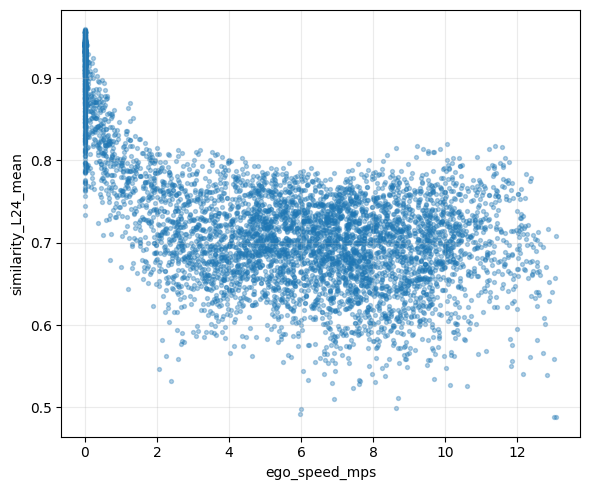

/home/moshekimhi_google_com/StreamPETR/outputs/policy_signal_stats/val/explore/speed_vs_l24_similarity.png


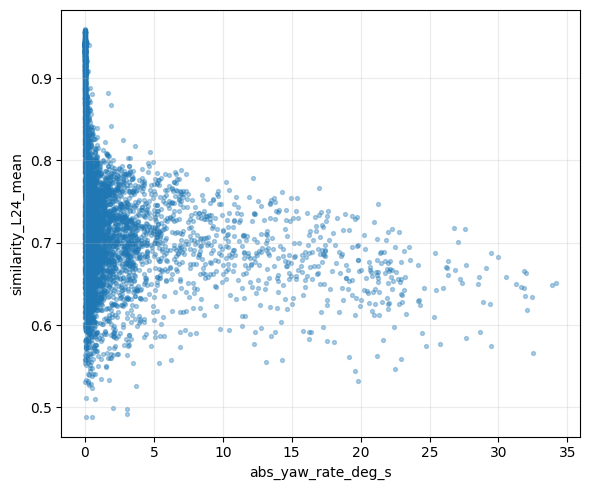

/home/moshekimhi_google_com/StreamPETR/outputs/policy_signal_stats/val/explore/yaw_rate_vs_l24_similarity.png


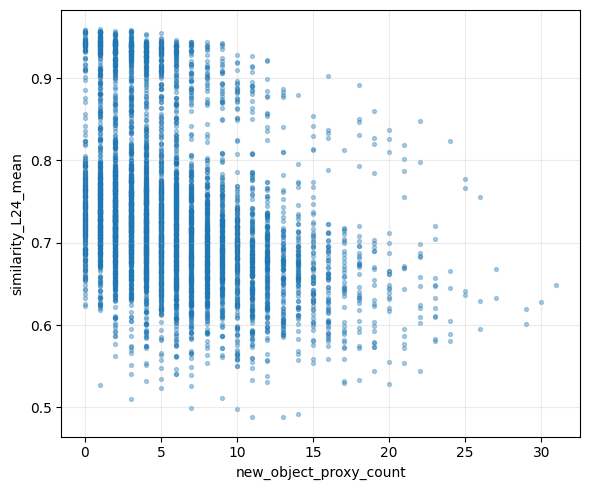

/home/moshekimhi_google_com/StreamPETR/outputs/policy_signal_stats/val/explore/new_proxy_vs_l24_similarity.png


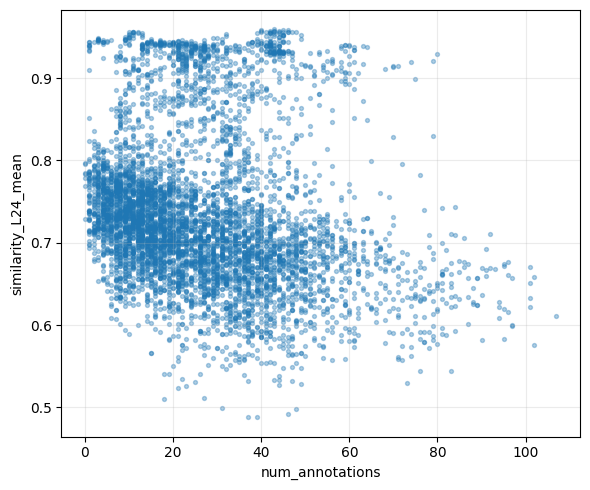

/home/moshekimhi_google_com/StreamPETR/outputs/policy_signal_stats/val/explore/num_annotations_vs_l24_similarity.png


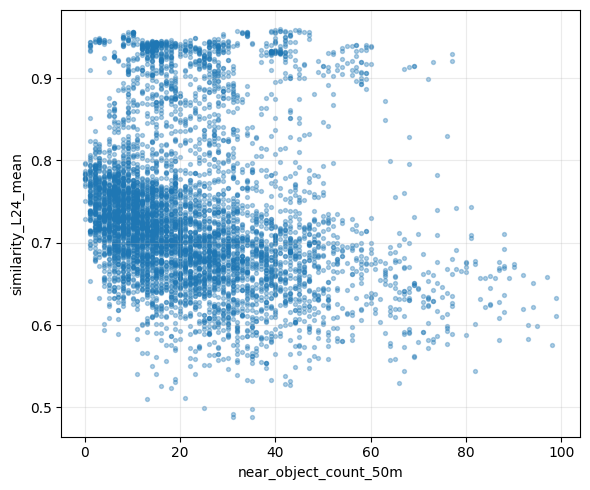

/home/moshekimhi_google_com/StreamPETR/outputs/policy_signal_stats/val/explore/near50_vs_l24_similarity.png


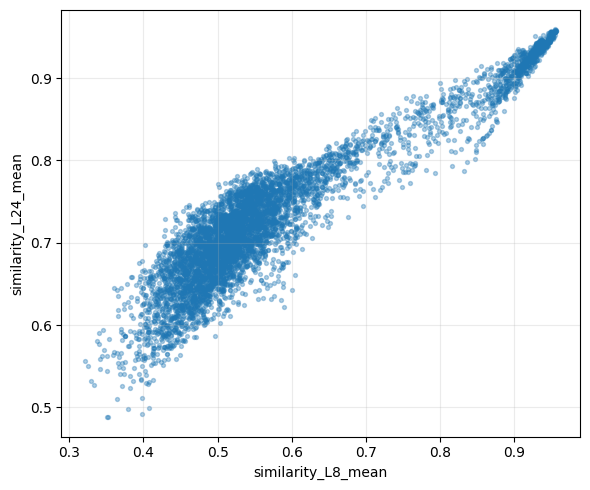

/home/moshekimhi_google_com/StreamPETR/outputs/policy_signal_stats/val/explore/l8_mean_vs_l24_mean.png


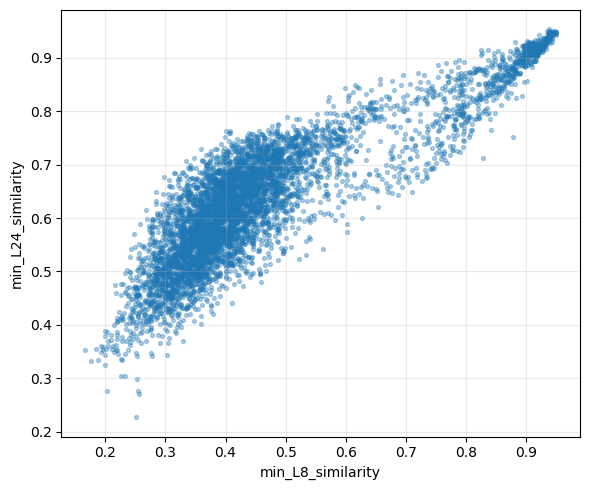

/home/moshekimhi_google_com/StreamPETR/outputs/policy_signal_stats/val/explore/worst_l8_vs_worst_l24.png


In [6]:
scatter_specs = [
    ("ego_speed_mps", "similarity_L24_mean", "speed_vs_l24_similarity.png"),
    ("abs_yaw_rate_deg_s", "similarity_L24_mean", "yaw_rate_vs_l24_similarity.png"),
    ("new_object_proxy_count", "similarity_L24_mean", "new_proxy_vs_l24_similarity.png"),
    ("num_annotations", "similarity_L24_mean", "num_annotations_vs_l24_similarity.png"),
    ("near_object_count_50m", "similarity_L24_mean", "near50_vs_l24_similarity.png"),
    ("similarity_L8_mean", "similarity_L24_mean", "l8_mean_vs_l24_mean.png"),
    ("min_L8_similarity", "min_L24_similarity", "worst_l8_vs_worst_l24.png"),
]

for x, y, name in scatter_specs:
    if x not in df.columns or y not in df.columns:
        continue
    plt.figure(figsize=(6, 5))
    plt.scatter(df[x], df[y], s=8, alpha=0.35)
    plt.xlabel(x)
    plt.ylabel(y)
    plt.grid(alpha=0.25)
    savefig(name)


,frames
difficulty,
hard,865
medium,3890
easy,1114


hard <0.65, 0.65 < medium < 0.8, 0.8 <easy


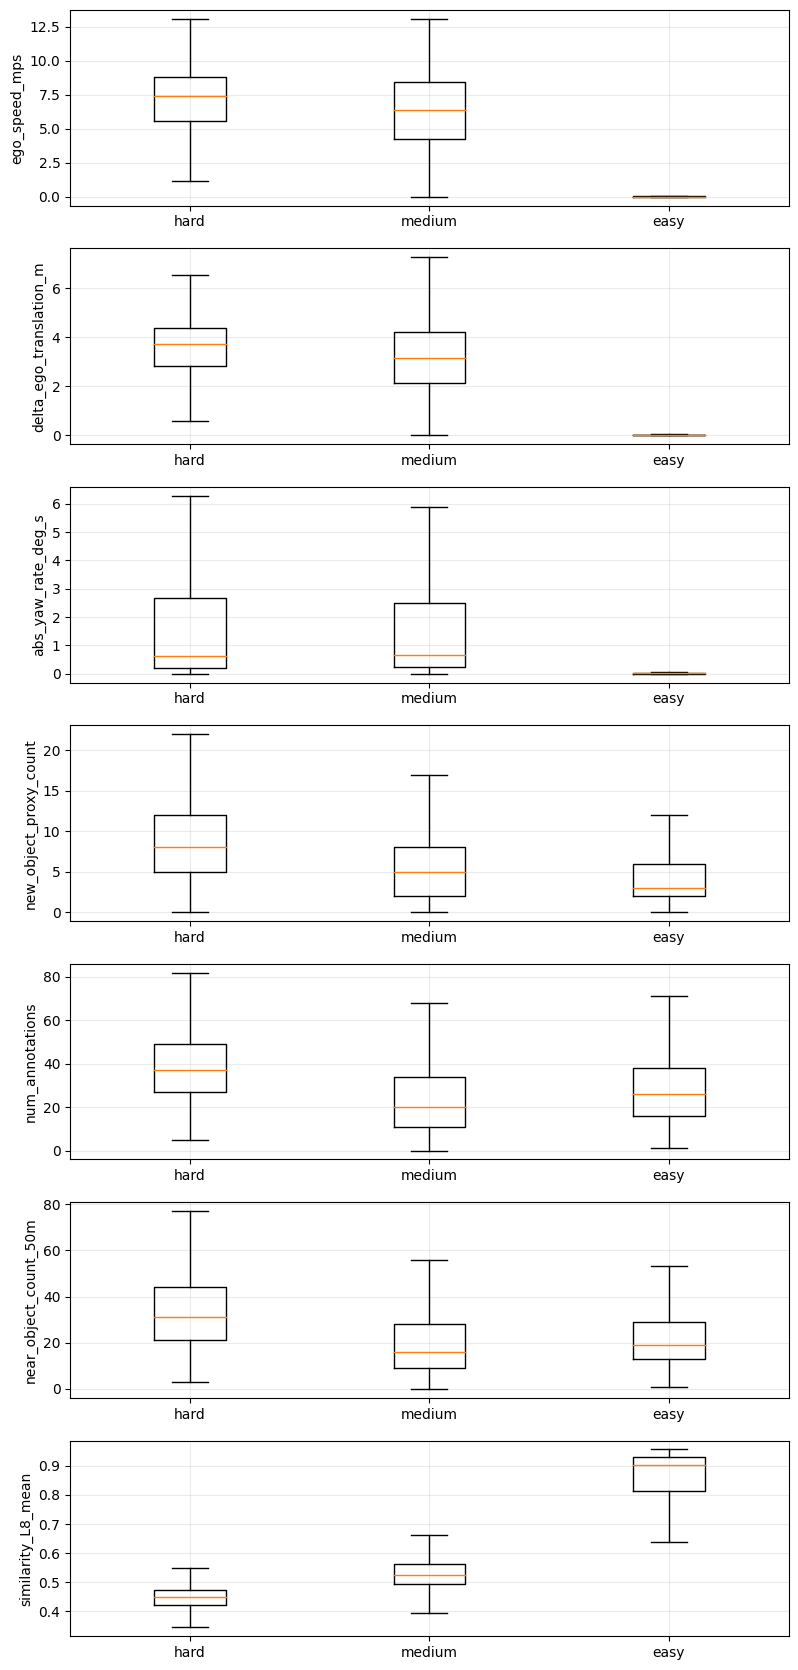

/home/moshekimhi_google_com/StreamPETR/outputs/policy_signal_stats/val/explore/difficulty_feature_boxplots.png


In [7]:
label_counts = df["difficulty"].value_counts().reindex(["hard", "medium", "easy"])
display(label_counts.to_frame("frames"))
print(f"hard <0.65, 0.65 < medium < 0.8, 0.8 <easy")
features_for_labels = [
    "ego_speed_mps",
    "delta_ego_translation_m",
    "abs_yaw_rate_deg_s",
    "new_object_proxy_count",
    "num_annotations",
    "near_object_count_50m",
    "similarity_L8_mean",
]
features_for_labels = [c for c in features_for_labels if c in df.columns]

fig, axes = plt.subplots(len(features_for_labels), 1, figsize=(8, 2.4 * len(features_for_labels)))
if len(features_for_labels) == 1:
    axes = [axes]
for ax, col in zip(axes, features_for_labels):
    groups = [df.loc[df["difficulty"] == label, col].dropna() for label in ["hard", "medium", "easy"]]
    ax.boxplot(groups, labels=["hard", "medium", "easy"], showfliers=False)
    ax.set_ylabel(col)
    ax.grid(alpha=0.25)
savefig("difficulty_feature_boxplots.png")


difficulty,hard,medium,easy,total
count,150.000000,150.000000,150.000000,150.000000
mean,5.766667,25.933333,7.426667,39.126667
std,7.837628,11.325369,11.511504,0.594117
min,0.000000,0.000000,0.000000,38.000000
25%,0.000000,20.000000,0.000000,39.000000
50%,2.000000,28.500000,1.000000,39.000000
75%,8.750000,34.750000,11.000000,39.000000
max,32.000000,40.000000,40.000000,40.000000


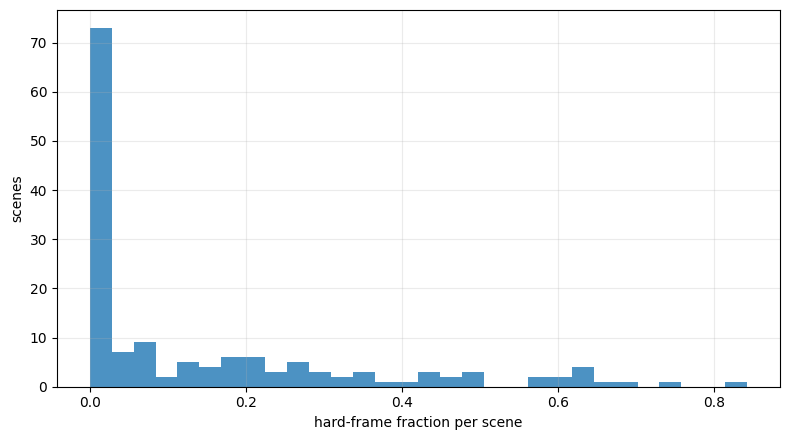

/home/moshekimhi_google_com/StreamPETR/outputs/policy_signal_stats/val/explore/per_scene_hard_fraction.png


In [8]:
scene_balance = (
    df.groupby(["scene_token", "difficulty"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["hard", "medium", "easy"], fill_value=0)
)
scene_balance["total"] = scene_balance.sum(axis=1)
scene_balance_fraction = scene_balance.div(scene_balance["total"], axis=0).drop(columns="total")

display(scene_balance.describe())

plt.figure(figsize=(8, 4.5))
plt.hist(scene_balance_fraction["hard"], bins=30, alpha=0.8)
plt.xlabel("hard-frame fraction per scene")
plt.ylabel("scenes")
plt.grid(alpha=0.25)
savefig("per_scene_hard_fraction.png")


,similarity_L24_mean,l24_drift
l24_drift,-1.000000,1.000000
delta_ego_translation_m,-0.552618,0.552618
ego_speed_mps,-0.550319,0.550319
abs_yaw_rate_deg_s,-0.446696,0.446696
abs_yaw_accel_deg_s2,-0.435132,0.435132
disappeared_object_proxy_count,-0.404300,0.404300
new_object_proxy_count,-0.394483,0.394483
near_object_count_50m,-0.291701,0.291701
num_annotations,-0.278882,0.278882
camera_annotation_count,-0.264080,0.264080


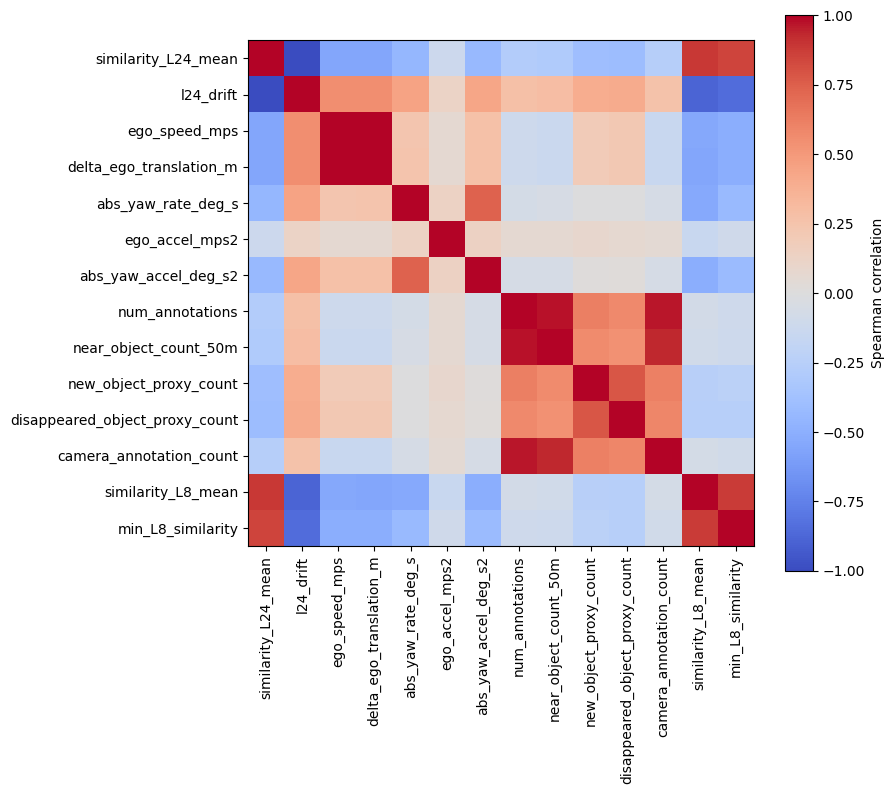

/home/moshekimhi_google_com/StreamPETR/outputs/policy_signal_stats/val/explore/stage_a_spearman_correlation_matrix.png


In [9]:
corr_cols = [
    "similarity_L24_mean",
    "l24_drift",
    "ego_speed_mps",
    "delta_ego_translation_m",
    "abs_yaw_rate_deg_s",
    "ego_accel_mps2",
    "abs_yaw_accel_deg_s2",
    "num_annotations",
    "near_object_count_50m",
    "new_object_proxy_count",
    "disappeared_object_proxy_count",
    "camera_annotation_count",
    "similarity_L8_mean",
    "min_L8_similarity",
]
corr_cols = [c for c in corr_cols if c in df.columns]
corr = df[corr_cols].corr(method="spearman")

display(corr[["similarity_L24_mean", "l24_drift"]].sort_values("similarity_L24_mean"))

plt.figure(figsize=(9, 8))
plt.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
plt.colorbar(label="Spearman correlation")
plt.xticks(range(len(corr_cols)), corr_cols, rotation=90)
plt.yticks(range(len(corr_cols)), corr_cols)
savefig("stage_a_spearman_correlation_matrix.png")


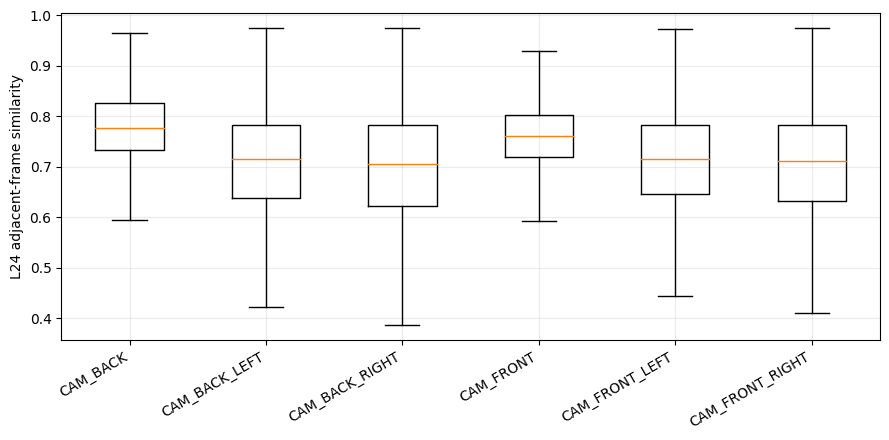

/home/moshekimhi_google_com/StreamPETR/outputs/policy_signal_stats/val/explore/per_camera_l24_similarity_boxplot.png


,camera,spearman_L8_to_L24
0,CAM_BACK,0.894411
2,CAM_BACK_RIGHT,0.883809
5,CAM_FRONT_RIGHT,0.881030
3,CAM_FRONT,0.867883
4,CAM_FRONT_LEFT,0.849673
1,CAM_BACK_LEFT,0.847988


,worst_L24_frames
camera,
CAM_BACK_RIGHT,1495
CAM_BACK_LEFT,1410
CAM_FRONT_RIGHT,1243
CAM_FRONT_LEFT,1141
CAM_FRONT,467
CAM_BACK,113


In [10]:
l24_cam_cols = [c for c in df.columns if c.startswith("similarity_L24_CAM_")]
l8_cam_cols = [c for c in df.columns if c.startswith("similarity_L8_CAM_")]

plt.figure(figsize=(9, 4.5))
plt.boxplot([df[c].dropna() for c in l24_cam_cols], labels=[c.replace("similarity_L24_", "") for c in l24_cam_cols], showfliers=False)
plt.ylabel("L24 adjacent-frame similarity")
plt.xticks(rotation=30, ha="right")
plt.grid(alpha=0.25)
savefig("per_camera_l24_similarity_boxplot.png")

camera_corr = []
for l8_col in l8_cam_cols:
    camera = l8_col.replace("similarity_L8_", "")
    l24_col = f"similarity_L24_{camera}"
    if l24_col in df.columns:
        camera_corr.append((camera, df[[l8_col, l24_col]].corr(method="spearman").iloc[0, 1]))

camera_corr_df = pd.DataFrame(camera_corr, columns=["camera", "spearman_L8_to_L24"])
display(camera_corr_df.sort_values("spearman_L8_to_L24", ascending=False))

worst_l24_camera = df[l24_cam_cols].idxmin(axis=1).str.replace("similarity_L24_", "", regex=False)
display(worst_l24_camera.value_counts().rename_axis("camera").to_frame("worst_L24_frames"))


# Stage B: Grouped CV Baselines

The model predicts `similarity_L24_mean`. Use the MAE directly as similarity error; drift error is identical because drift is `1 - similarity`.


In [11]:
def evaluate_feature_set(features, target="similarity_L24_mean", n_splits=5, permutation=False):
    rows = []
    importances = []
    splitter = GroupKFold(n_splits=n_splits)
    for fold, (train_idx, test_idx) in enumerate(splitter.split(df[features], df[target], df["scene_token"]), 1):
        model = make_pipeline(
            SimpleImputer(strategy="median"),
            HistGradientBoostingRegressor(random_state=fold),
        )
        model.fit(df.iloc[train_idx][features], df.iloc[train_idx][target])
        pred = model.predict(df.iloc[test_idx][features])
        rows.append({
            "fold": fold,
            "r2": r2_score(df.iloc[test_idx][target], pred),
            "mae": mean_absolute_error(df.iloc[test_idx][target], pred),
        })
        if permutation:
            pi = permutation_importance(
                model,
                df.iloc[test_idx][features],
                df.iloc[test_idx][target],
                scoring="neg_mean_absolute_error",
                n_repeats=10,
                random_state=100 + fold,
                n_jobs=1,
            )
            importances.append(pi.importances_mean)
    result = pd.DataFrame(rows)
    if permutation:
        importance = pd.Series(np.vstack(importances).mean(axis=0), index=features).sort_values(ascending=False)
    else:
        importance = None
    return result, importance

summary_rows = []
fold_tables = {}
importance_tables = {}

for name, features in FEATURE_SETS.items():
    fold_result, importance = evaluate_feature_set(features, permutation=True)
    fold_tables[name] = fold_result
    importance_tables[name] = importance
    summary_rows.append({
        "feature_set": name,
        "n_features": len(features),
        "r2_mean": fold_result["r2"].mean(),
        "r2_std": fold_result["r2"].std(ddof=0),
        "mae_mean": fold_result["mae"].mean(),
        "mae_std": fold_result["mae"].std(ddof=0),
    })

summary = pd.DataFrame(summary_rows).sort_values("mae_mean")
display(summary)
summary.to_csv(EXPLORE_DIR / "stage_b_grouped_cv_summary.csv", index=False)
summary


,feature_set,n_features,r2_mean,r2_std,mae_mean,mae_std
3,metadata_offline_plus_L8,49,0.952074,0.010301,0.014935,0.000591
2,metadata_online_plus_L8,22,0.902278,0.020875,0.021577,0.001022
1,metadata_offline,42,0.852971,0.036782,0.026788,0.001444
0,metadata_online,15,0.705952,0.042628,0.039065,0.002027


,feature_set,n_features,r2_mean,r2_std,mae_mean,mae_std
3,metadata_offline_plus_L8,49,0.952074,0.010301,0.014935,0.000591
2,metadata_online_plus_L8,22,0.902278,0.020875,0.021577,0.001022
1,metadata_offline,42,0.852971,0.036782,0.026788,0.001444
0,metadata_online,15,0.705952,0.042628,0.039065,0.002027


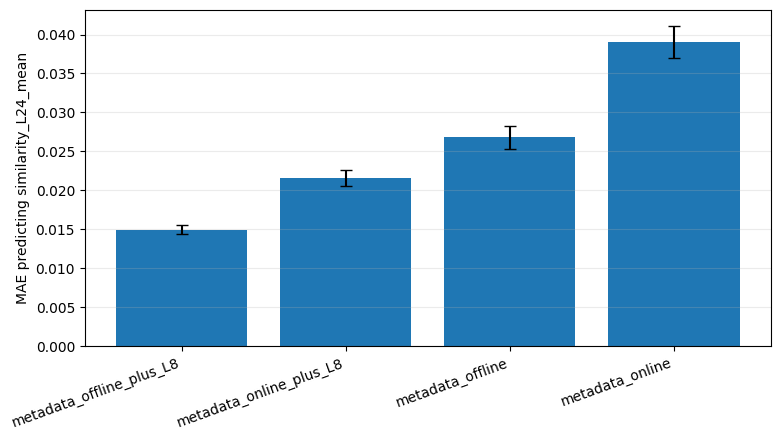

/home/moshekimhi_google_com/StreamPETR/outputs/policy_signal_stats/val/explore/stage_b_feature_set_mae.png


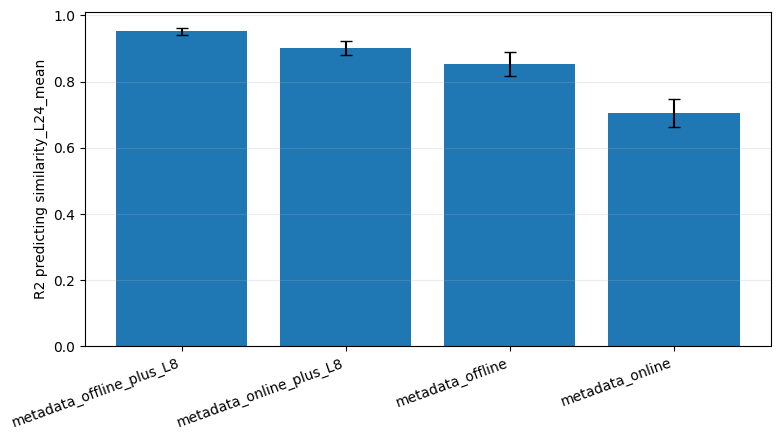

/home/moshekimhi_google_com/StreamPETR/outputs/policy_signal_stats/val/explore/stage_b_feature_set_r2.png


In [12]:
plt.figure(figsize=(8, 4.5))
order = summary["feature_set"].tolist()
x = np.arange(len(order))
plt.bar(x, summary.set_index("feature_set").loc[order, "mae_mean"])
plt.errorbar(x, summary.set_index("feature_set").loc[order, "mae_mean"], yerr=summary.set_index("feature_set").loc[order, "mae_std"], fmt="none", color="black", capsize=4)
plt.xticks(x, order, rotation=20, ha="right")
plt.ylabel("MAE predicting similarity_L24_mean")
plt.grid(axis="y", alpha=0.25)
savefig("stage_b_feature_set_mae.png")

plt.figure(figsize=(8, 4.5))
plt.bar(x, summary.set_index("feature_set").loc[order, "r2_mean"])
plt.errorbar(x, summary.set_index("feature_set").loc[order, "r2_mean"], yerr=summary.set_index("feature_set").loc[order, "r2_std"], fmt="none", color="black", capsize=4)
plt.xticks(x, order, rotation=20, ha="right")
plt.ylabel("R2 predicting similarity_L24_mean")
plt.grid(axis="y", alpha=0.25)
savefig("stage_b_feature_set_r2.png")


In [13]:
for name, importance in importance_tables.items():
    print()
    print(name)
    display(importance.head(12).rename("heldout_MAE_delta").to_frame())



metadata_online


,heldout_MAE_delta
delta_ego_translation_m,0.018363
ego_speed_mps,0.015297
abs_yaw_rate_deg_s,0.002261
ego_y_m,0.002212
ego_x_m,0.001586
ego_yaw_deg,0.001543
ego_accel_mps2,0.000834
abs_yaw_accel_deg_s2,0.000147
dt_s,0.000068
yaw_accel_deg_s2,0.000024



metadata_offline


,heldout_MAE_delta
delta_ego_translation_m,0.026328
ego_speed_mps,0.018865
abs_yaw_rate_deg_s,0.003539
max_2d_box_area_px,0.002468
min_camera_annotation_count,0.001964
avg_box_width_m,0.001058
min_object_distance_m,0.000994
max_object_speed_mps,0.000704
ego_accel_mps2,0.000593
near_object_count_20m,0.000576



metadata_online_plus_L8


,heldout_MAE_delta
similarity_L8_mean,0.064118
similarity_L8_CAM_BACK,0.001442
similarity_L8_CAM_FRONT_RIGHT,0.001163
ego_y_m,0.001146
similarity_L8_CAM_FRONT_LEFT,0.000994
similarity_L8_CAM_BACK_RIGHT,0.000788
similarity_L8_CAM_FRONT,0.000637
similarity_L8_CAM_BACK_LEFT,0.000605
ego_yaw_deg,0.000597
ego_x_m,0.000343



metadata_offline_plus_L8


,heldout_MAE_delta
similarity_L8_mean,0.066951
similarity_L8_CAM_BACK,0.001477
max_2d_box_area_px,0.001453
min_camera_annotation_count,0.001243
min_object_distance_m,0.000845
delta_ego_translation_m,0.000529
similarity_L8_CAM_FRONT_RIGHT,0.000402
similarity_L8_CAM_BACK_LEFT,0.000379
camera_annotation_count,0.000376
near_object_count_20m,0.000364


In [14]:
top5_rows = []
for name, importance in importance_tables.items():
    top5 = importance.head(5).index.tolist()
    fold_result, _ = evaluate_feature_set(top5, permutation=False)
    top5_rows.append({
        "source_feature_set": name,
        "top5_features": ", ".join(top5),
        "r2_mean": fold_result["r2"].mean(),
        "r2_std": fold_result["r2"].std(ddof=0),
        "mae_mean": fold_result["mae"].mean(),
        "mae_std": fold_result["mae"].std(ddof=0),
    })

top5_summary = pd.DataFrame(top5_rows).sort_values("mae_mean")
display(top5_summary)
top5_summary.to_csv(EXPLORE_DIR / "stage_b_top5_grouped_cv_summary.csv", index=False)


,source_feature_set,top5_features,r2_mean,r2_std,mae_mean,mae_std
3,metadata_offline_plus_L8,"similarity_L8_mean, similarity_L8_CAM_BACK, ma...",0.940150,0.011835,0.017033,0.000935
2,metadata_online_plus_L8,"similarity_L8_mean, similarity_L8_CAM_BACK, si...",0.894719,0.024026,0.022362,0.001119
1,metadata_offline,"delta_ego_translation_m, ego_speed_mps, abs_ya...",0.797196,0.019973,0.032613,0.001750
0,metadata_online,"delta_ego_translation_m, ego_speed_mps, abs_ya...",0.681257,0.066897,0.040551,0.002772


# Stage C: Difficulty Classification

This section predicts the exploratory `difficulty` label with cross-entropy. The labels are derived from `similarity_L24_mean`:

- `hard`: `< 0.65`
- `medium`: `0.65` to `< 0.80`
- `easy`: `>= 0.80`

Two classifiers are compared for each feature family:

- `HistGradientBoostingClassifier`
- small MLP with one hidden layer and softmax probabilities


In [15]:
from sklearn.neural_network import MLPClassifier
CLASS_LABELS = ["hard", "medium", "easy"]

def make_classifier(algorithm, fold):
    if algorithm == "hist_gradient_boosting":
        return make_pipeline(
            SimpleImputer(strategy="median"),
            HistGradientBoostingClassifier(random_state=fold),
        )
    if algorithm == "small_mlp_softmax":
        return make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            MLPClassifier(
                hidden_layer_sizes=(32,),
                activation="relu",
                solver="adam",
                alpha=1e-4,
                batch_size=256,
                learning_rate_init=1e-3,
                max_iter=300,
                early_stopping=True,
                n_iter_no_change=15,
                random_state=fold,
            ),
        )
    raise ValueError(f"unknown algorithm: {algorithm}")


def aligned_proba(model, x, labels=CLASS_LABELS):
    proba = model.predict_proba(x)
    classes = list(model.classes_ if hasattr(model, "classes_") else model[-1].classes_)
    out = np.zeros((len(x), len(labels)), dtype=float)
    for src_idx, cls in enumerate(classes):
        out[:, labels.index(cls)] = proba[:, src_idx]
    return out


In [16]:
def evaluate_classifier(features, algorithm, n_splits=5):
    rows = []
    confusion = np.zeros((len(CLASS_LABELS), len(CLASS_LABELS)), dtype=int)
    y = df["difficulty"].astype(str)
    splitter = GroupKFold(n_splits=n_splits)

    for fold, (train_idx, test_idx) in enumerate(splitter.split(df[features], y, df["scene_token"]), 1):
        model = make_classifier(algorithm, fold)
        model.fit(df.iloc[train_idx][features], y.iloc[train_idx])
        x_test = df.iloc[test_idx][features]
        y_test = y.iloc[test_idx]
        pred = model.predict(x_test)
        proba = aligned_proba(model, x_test)
        confusion += confusion_matrix(y_test, pred, labels=CLASS_LABELS)
        rows.append({
            "fold": fold,
            "cross_entropy": log_loss(y_test, proba, labels=CLASS_LABELS),
            "accuracy": accuracy_score(y_test, pred),
            "balanced_accuracy": balanced_accuracy_score(y_test, pred),
            "macro_f1": f1_score(y_test, pred, labels=CLASS_LABELS, average="macro"),
        })

    return pd.DataFrame(rows), pd.DataFrame(confusion, index=CLASS_LABELS, columns=CLASS_LABELS)


In [17]:
classification_rows = []
classification_folds = {}
classification_confusions = {}

for feature_set_name, features in FEATURE_SETS.items():
    for algorithm in ["hist_gradient_boosting", "small_mlp_softmax"]:
        fold_result, confusion = evaluate_classifier(features, algorithm)
        key = f"{feature_set_name}__{algorithm}"
        classification_folds[key] = fold_result
        classification_confusions[key] = confusion
        classification_rows.append({
            "feature_set": feature_set_name,
            "algorithm": algorithm,
            "n_features": len(features),
            "cross_entropy_mean": fold_result["cross_entropy"].mean(),
            "cross_entropy_std": fold_result["cross_entropy"].std(ddof=0),
            "accuracy_mean": fold_result["accuracy"].mean(),
            "accuracy_std": fold_result["accuracy"].std(ddof=0),
            "balanced_accuracy_mean": fold_result["balanced_accuracy"].mean(),
            "balanced_accuracy_std": fold_result["balanced_accuracy"].std(ddof=0),
            "macro_f1_mean": fold_result["macro_f1"].mean(),
            "macro_f1_std": fold_result["macro_f1"].std(ddof=0),
        })

classification_summary = pd.DataFrame(classification_rows).sort_values("cross_entropy_mean")
display(classification_summary)
classification_summary.to_csv(EXPLORE_DIR / "stage_c_difficulty_classification_summary.csv", index=False)
classification_summary


,feature_set,algorithm,n_features,cross_entropy_mean,cross_entropy_std,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,macro_f1_mean,macro_f1_std
1,metadata_online,small_mlp_softmax,15,4.535935,0.598910,0.803715,0.019693,0.630036,0.016170,0.594643,0.011431
3,metadata_offline,small_mlp_softmax,42,5.389748,0.290808,0.832340,0.020603,0.748128,0.044933,0.761173,0.037320
5,metadata_online_plus_L8,small_mlp_softmax,22,6.860237,0.855866,0.865052,0.013455,0.785134,0.012797,0.800010,0.020125
7,metadata_offline_plus_L8,small_mlp_softmax,49,8.503483,1.057679,0.890952,0.014355,0.841299,0.014957,0.850247,0.019741
0,metadata_online,hist_gradient_boosting,15,8.827555,0.474186,0.799286,0.027287,0.656131,0.021987,0.657733,0.014897
2,metadata_offline,hist_gradient_boosting,42,9.847712,0.394167,0.856022,0.016625,0.767255,0.022601,0.785108,0.024030
4,metadata_online_plus_L8,hist_gradient_boosting,22,12.020718,0.297938,0.866588,0.008313,0.803761,0.011395,0.810052,0.016549
6,metadata_offline_plus_L8,hist_gradient_boosting,49,12.851006,0.274600,0.905438,0.010633,0.860839,0.010573,0.868421,0.019916


,feature_set,algorithm,n_features,cross_entropy_mean,cross_entropy_std,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,macro_f1_mean,macro_f1_std
1,metadata_online,small_mlp_softmax,15,4.535935,0.598910,0.803715,0.019693,0.630036,0.016170,0.594643,0.011431
3,metadata_offline,small_mlp_softmax,42,5.389748,0.290808,0.832340,0.020603,0.748128,0.044933,0.761173,0.037320
5,metadata_online_plus_L8,small_mlp_softmax,22,6.860237,0.855866,0.865052,0.013455,0.785134,0.012797,0.800010,0.020125
7,metadata_offline_plus_L8,small_mlp_softmax,49,8.503483,1.057679,0.890952,0.014355,0.841299,0.014957,0.850247,0.019741
0,metadata_online,hist_gradient_boosting,15,8.827555,0.474186,0.799286,0.027287,0.656131,0.021987,0.657733,0.014897
2,metadata_offline,hist_gradient_boosting,42,9.847712,0.394167,0.856022,0.016625,0.767255,0.022601,0.785108,0.024030
4,metadata_online_plus_L8,hist_gradient_boosting,22,12.020718,0.297938,0.866588,0.008313,0.803761,0.011395,0.810052,0.016549
6,metadata_offline_plus_L8,hist_gradient_boosting,49,12.851006,0.274600,0.905438,0.010633,0.860839,0.010573,0.868421,0.019916


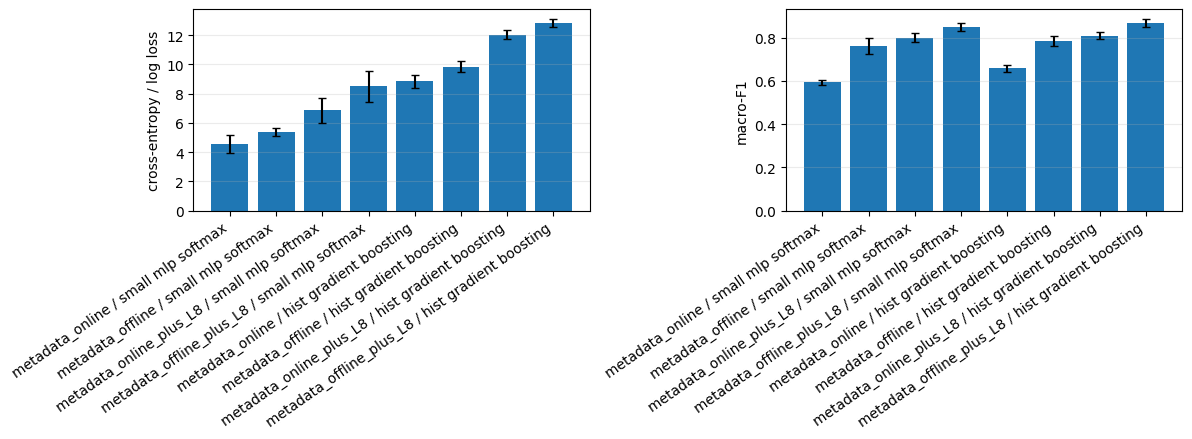

/home/moshekimhi_google_com/StreamPETR/outputs/policy_signal_stats/val/explore/stage_c_difficulty_classification_metrics.png


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
plot_df = classification_summary.copy()
plot_df["name"] = plot_df["feature_set"] + " / " + plot_df["algorithm"].str.replace("_", " ")

x = np.arange(len(plot_df))
axes[0].bar(x, plot_df["cross_entropy_mean"])
axes[0].errorbar(x, plot_df["cross_entropy_mean"], yerr=plot_df["cross_entropy_std"], fmt="none", color="black", capsize=3)
axes[0].set_ylabel("cross-entropy / log loss")
axes[0].set_xticks(x)
axes[0].set_xticklabels(plot_df["name"], rotation=35, ha="right")
axes[0].grid(axis="y", alpha=0.25)

axes[1].bar(x, plot_df["macro_f1_mean"])
axes[1].errorbar(x, plot_df["macro_f1_mean"], yerr=plot_df["macro_f1_std"], fmt="none", color="black", capsize=3)
axes[1].set_ylabel("macro-F1")
axes[1].set_xticks(x)
axes[1].set_xticklabels(plot_df["name"], rotation=35, ha="right")
axes[1].grid(axis="y", alpha=0.25)

savefig("stage_c_difficulty_classification_metrics.png")


In [19]:
for key, confusion in classification_confusions.items():
    print(key)
    display(confusion)


metadata_online__hist_gradient_boosting


,hard,medium,easy
hard,128,737,0
medium,278,3543,69
easy,0,94,1020


metadata_online__small_mlp_softmax


,hard,medium,easy
hard,11,853,1
medium,64,3671,155
easy,0,79,1035


metadata_offline__hist_gradient_boosting


...

,hard,medium,easy
hard,423,442,0
medium,215,3622,53
easy,0,82,1032


metadata_offline_plus_L8__hist_gradient_boosting


,hard,medium,easy
hard,599,266,0
medium,163,3667,60
easy,0,66,1048


metadata_offline_plus_L8__small_mlp_softmax


,hard,medium,easy
hard,581,284,0
medium,198,3628,64
easy,0,94,1020


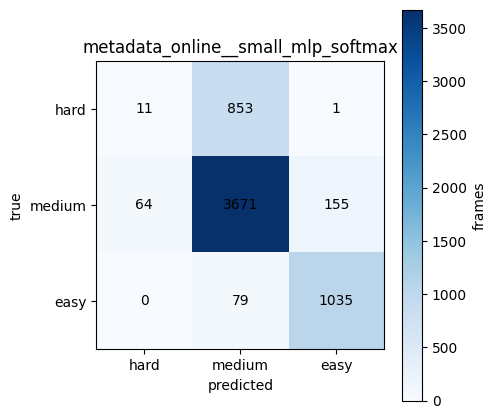

/home/moshekimhi_google_com/StreamPETR/outputs/policy_signal_stats/val/explore/stage_c_best_confusion_matrix.png


In [20]:
best_key = (
    classification_summary.iloc[0]["feature_set"]
    + "__"
    + classification_summary.iloc[0]["algorithm"]
)
best_confusion = classification_confusions[best_key]

plt.figure(figsize=(5, 4.5))
plt.imshow(best_confusion, cmap="Blues")
plt.title(best_key)
plt.colorbar(label="frames")
plt.xticks(range(len(CLASS_LABELS)), CLASS_LABELS)
plt.yticks(range(len(CLASS_LABELS)), CLASS_LABELS)
plt.xlabel("predicted")
plt.ylabel("true")
for i in range(len(CLASS_LABELS)):
    for j in range(len(CLASS_LABELS)):
        plt.text(j, i, str(best_confusion.iloc[i, j]), ha="center", va="center")
savefig("stage_c_best_confusion_matrix.png")


## Stage D: Previous GT Summary and Previous L8 Drift

This section compares eight deployability-oriented feature strategies for the same `easy/medium/hard` target from `similarity_L24_mean`:

1. online metadata only
2. online metadata plus previous-frame GT/offline summary fields
3. previous adjacent-frame L8 drift only
4. online metadata plus previous adjacent-frame L8 drift
5. previous adjacent-frame L12 drift only
6. online metadata plus previous adjacent-frame L12 drift
7. online metadata plus previous-frame GT/offline summary fields plus previous adjacent-frame L8 drift
8. online metadata plus previous-frame GT/offline summary fields plus previous adjacent-frame L12 drift

At time `t`, `prev_similarity_L8_*` is the row `t-1` L8 similarity, i.e. `sim(L8_{t-2}, L8_{t-1})`. This matches the online timing where current-frame exit must be chosen before computing current-frame L8 unless a separate current probe is charged.


In [ ]:
OFFLINE_GT_ONLY = [c for c in OFFLINE_METADATA if c not in ONLINE_METADATA]

df_prev = df.sort_values(["scene_token", "frame_number"]).copy()
for col in OFFLINE_GT_ONLY:
    df_prev[f"prev_gt_{col}"] = df_prev.groupby("scene_token")[col].shift(1)
for col in L8_FEATURES:
    df_prev[f"prev_{col}"] = df_prev.groupby("scene_token")[col].shift(1)

PREV_GT_FEATURES = [f"prev_gt_{c}" for c in OFFLINE_GT_ONLY]
PREV_L8_DRIFT_FEATURES = [f"prev_{c}" for c in L8_FEATURES]

# Fair comparison on frames where both previous GT summary and previous L8 drift are available.
eval_df = df_prev.dropna(subset=PREV_GT_FEATURES + PREV_L8_DRIFT_FEATURES, how="any").copy()

PREV_FEATURE_SETS = {
    "metadata_online": ONLINE_METADATA,
    "metadata_online_plus_prev_gt": ONLINE_METADATA + PREV_GT_FEATURES,
    "metadata_online_plus_prev_gt_plus_prev_l8_drift": ONLINE_METADATA + PREV_GT_FEATURES + PREV_L8_DRIFT_FEATURES,
}

print(f"rows used: {len(eval_df)}")
print(eval_df["difficulty"].value_counts().reindex(CLASS_LABELS))
pd.DataFrame({"feature_set": PREV_FEATURE_SETS.keys(), "n_features": [len(v) for v in PREV_FEATURE_SETS.values()]})


In [ ]:
def evaluate_classifier_on_table(table, features, algorithm, n_splits=5):
    rows = []
    confusion = np.zeros((len(CLASS_LABELS), len(CLASS_LABELS)), dtype=int)
    y = table["difficulty"].astype(str)
    splitter = GroupKFold(n_splits=n_splits)
    for fold, (train_idx, test_idx) in enumerate(splitter.split(table[features], y, table["scene_token"]), 1):
        model = make_classifier(algorithm, fold)
        model.fit(table.iloc[train_idx][features], y.iloc[train_idx])
        x_test = table.iloc[test_idx][features]
        y_test = y.iloc[test_idx]
        pred = model.predict(x_test)
        proba = aligned_proba(model, x_test)
        confusion += confusion_matrix(y_test, pred, labels=CLASS_LABELS)
        rows.append({
            "fold": fold,
            "cross_entropy": log_loss(y_test, proba, labels=CLASS_LABELS),
            "accuracy": accuracy_score(y_test, pred),
            "balanced_accuracy": balanced_accuracy_score(y_test, pred),
            "macro_f1": f1_score(y_test, pred, labels=CLASS_LABELS, average="macro"),
        })
    return pd.DataFrame(rows), pd.DataFrame(confusion, index=CLASS_LABELS, columns=CLASS_LABELS)

prev_rows = []
prev_confusions = {}
for feature_set_name, features in PREV_FEATURE_SETS.items():
    for algorithm in ["hist_gradient_boosting", "small_mlp_softmax"]:
        fold_result, confusion = evaluate_classifier_on_table(eval_df, features, algorithm)
        prev_confusions[f"{feature_set_name}__{algorithm}"] = confusion
        prev_rows.append({
            "feature_set": feature_set_name,
            "algorithm": algorithm,
            "n_features": len(features),
            "n_frames": len(eval_df),
            "cross_entropy_mean": fold_result["cross_entropy"].mean(),
            "cross_entropy_std": fold_result["cross_entropy"].std(ddof=0),
            "accuracy_mean": fold_result["accuracy"].mean(),
            "accuracy_std": fold_result["accuracy"].std(ddof=0),
            "balanced_accuracy_mean": fold_result["balanced_accuracy"].mean(),
            "balanced_accuracy_std": fold_result["balanced_accuracy"].std(ddof=0),
            "macro_f1_mean": fold_result["macro_f1"].mean(),
            "macro_f1_std": fold_result["macro_f1"].std(ddof=0),
        })

prev_summary = pd.DataFrame(prev_rows).sort_values(["macro_f1_mean", "balanced_accuracy_mean"], ascending=False)
display(prev_summary)
prev_summary.to_csv(EXPLORE_DIR / "stage_c_prev_gt_prev_l8_drift_classification_summary.csv", index=False)

best_key = prev_summary.iloc[0]["feature_set"] + "__" + prev_summary.iloc[0]["algorithm"]
display(prev_confusions[best_key])


## Stage E: Difficulty Threshold Sensitivity

This section checks whether the `easy/medium/hard` boundaries should be set by fixed values or validation-set quantiles. It uses the strongest Stage D feature set, `online + previous GT summary + previous L12 drift`, and grouped CV by scene.

Recommended 3-level scheme: `q20/q80`, which gives conservative hard/easy tails and improves macro-F1 over the fixed `0.65/0.80` bins.

Recommended 4-level scheme: `q20/q70/q90`, mapped to `hard/medium/easy/very_easy`. This keeps full-refresh hard frames and very-cheap easy frames conservative instead of forcing equal quartiles.


In [ ]:
THRESHOLD_FEATURES = ONLINE_METADATA + PREV_GT_FEATURES + PREV_L12_DRIFT_FEATURES
threshold_df = eval_df.copy()
target = threshold_df["similarity_L24_mean"]
display(target.quantile([0.10, 0.20, 0.25, 0.50, 0.60, 0.70, 0.75, 0.80, 0.85, 0.90]).rename("similarity_L24_mean"))

def evaluate_threshold_labels(table, features, y, labels):
    rows = []
    for fold, (train_idx, test_idx) in enumerate(GroupKFold(n_splits=5).split(table[features], y, table["scene_token"]), 1):
        model = make_pipeline(SimpleImputer(strategy="median"), HistGradientBoostingClassifier(random_state=fold))
        model.fit(table.iloc[train_idx][features], y.iloc[train_idx])
        pred = model.predict(table.iloc[test_idx][features])
        rows.append({
            "fold": fold,
            "accuracy": accuracy_score(y.iloc[test_idx], pred),
            "balanced_accuracy": balanced_accuracy_score(y.iloc[test_idx], pred),
            "macro_f1": f1_score(y.iloc[test_idx], pred, labels=labels, average="macro"),
        })
    return pd.DataFrame(rows)

threshold_rows = []
schemes3 = {
    "current_0.65_0.80": (0.65, 0.80),
    "q20_q80": tuple(target.quantile([0.20, 0.80]).values),
    "q25_q75": tuple(target.quantile([0.25, 0.75]).values),
    "tertiles_q33_q67": tuple(target.quantile([1/3, 2/3]).values),
}
labels3 = ["hard", "medium", "easy"]
for name, (lo, hi) in schemes3.items():
    y = pd.cut(target, bins=[-np.inf, lo, hi, np.inf], labels=labels3).astype(str)
    result = evaluate_threshold_labels(threshold_df, THRESHOLD_FEATURES, y, labels3)
    counts = y.value_counts().reindex(labels3)
    threshold_rows.append({"levels": 3, "scheme": name, "t1": lo, "t2": hi, "t3": np.nan, "hard": counts["hard"], "medium": counts["medium"], "easy": counts["easy"], "very_easy": np.nan, "accuracy_mean": result["accuracy"].mean(), "balanced_accuracy_mean": result["balanced_accuracy"].mean(), "macro_f1_mean": result["macro_f1"].mean(), "macro_f1_std": result["macro_f1"].std(ddof=0)})

schemes4 = {
    "strict_easy_q20_q70_q90": tuple(target.quantile([0.20, 0.70, 0.90]).values),
    "conservative_q20_q60_q85": tuple(target.quantile([0.20, 0.60, 0.85]).values),
    "balanced_tail_q20_q50_q80": tuple(target.quantile([0.20, 0.50, 0.80]).values),
    "current_style_0.65_0.75_0.80": (0.65, 0.75, 0.80),
    "quartiles_q25_q50_q75": tuple(target.quantile([0.25, 0.50, 0.75]).values),
}
labels4 = ["hard", "medium", "easy", "very_easy"]
for name, (t1, t2, t3) in schemes4.items():
    y = pd.cut(target, bins=[-np.inf, t1, t2, t3, np.inf], labels=labels4).astype(str)
    result = evaluate_threshold_labels(threshold_df, THRESHOLD_FEATURES, y, labels4)
    counts = y.value_counts().reindex(labels4)
    threshold_rows.append({"levels": 4, "scheme": name, "t1": t1, "t2": t2, "t3": t3, "hard": counts["hard"], "medium": counts["medium"], "easy": counts["easy"], "very_easy": counts["very_easy"], "accuracy_mean": result["accuracy"].mean(), "balanced_accuracy_mean": result["balanced_accuracy"].mean(), "macro_f1_mean": result["macro_f1"].mean(), "macro_f1_std": result["macro_f1"].std(ddof=0)})

threshold_summary = pd.DataFrame(threshold_rows).sort_values(["levels", "macro_f1_mean"], ascending=[True, False])
display(threshold_summary)
threshold_summary.to_csv(EXPLORE_DIR / "stage_d_threshold_sensitivity_summary.csv", index=False)
